# Actividad 8 | Regresión No Lineal
Base de datos: Existencias_04_09_2026 (CLV)

Variables numéricas: existencias, valor_total_inventario y costo_unitario (calculada)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

In [2]:
existencias = pd.read_csv('Existencias_04_09_2026.csv')
existencias.head()

,articulo_id,nombre_articulo,marca,nombre_almacen,existencias,valor_total_inventario
0,97759,10L MAX BUILD TRAY,Asiga,Almacén General,4,17308.44
1,295121,1L MAX LOW FORCE BUILD TRAY,Asiga,Almacén General,4,3749.14
2,309437,2-2 VALVULA DIRECCIONAL AGUA AIRE,Amann Girrbach,Almacén General,2,6458.84
3,85167,2L MAX BUILD PLASTIC TRAY FOR MAX 3D PRINTER,Asiga,Almacén General,1,1565.35
4,295124,2L ULTRA ULTRAGLOSS BUILD TRAY,Asiga,Almacén General,1,2905.36


In [3]:
existencias.info()

<class 'pandas.DataFrame'>
RangeIndex: 2950 entries, 0 to 2949
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   articulo_id             2950 non-null   int64  
 1   nombre_articulo         2950 non-null   str    
 2   marca                   2950 non-null   str    
 3   nombre_almacen          2950 non-null   str    
 4   existencias             2950 non-null   int64  
 5   valor_total_inventario  2950 non-null   float64
dtypes: float64(1), int64(2), str(3)
memory usage: 273.4 KB


## 1. Preprocesamiento
### Valores nulos

In [4]:
existencias.isnull().sum()

articulo_id               0
nombre_articulo           0
marca                     0
nombre_almacen            0
existencias               0
valor_total_inventario    0
dtype: int64

No hay nulos en ninguna columna. Reviso también si hay registros duplicados o con existencias en 0 o negativas (no tienen sentido para el análisis).

In [5]:
print('Duplicados:', existencias.duplicated().sum())
print('Existencias <= 0:', (existencias['existencias'] <= 0).sum())
print('Valor inventario <= 0:', (existencias['valor_total_inventario'] <= 0).sum())

Duplicados: 0
Existencias <= 0: 2
Valor inventario <= 0: 0


In [6]:
existencias = existencias[existencias['existencias'] > 0]
existencias.shape

(2948, 6)

### Transformaciones
Se crea la variable costo_unitario = valor_total_inventario / existencias. En la actividad pasada vimos que el valor depende mucho del costo de cada artículo, entonces vale la pena analizarla.

In [7]:
existencias['costo_unitario'] = existencias['valor_total_inventario'] / existencias['existencias']
num = existencias[['existencias', 'valor_total_inventario', 'costo_unitario']]
num.describe()

,existencias,valor_total_inventario,costo_unitario
count,2948.000000,2.948000e+03,2948.000000
mean,27.712347,2.261585e+04,2619.076004
std,82.250699,1.429765e+05,21999.289166
min,1.000000,2.698000e+01,9.814194
25%,3.000000,1.151520e+03,241.229821
50%,7.000000,2.462675e+03,292.259365
75%,15.000000,6.618945e+03,649.662464
max,1439.000000,3.644807e+06,674013.000000


### Outliers

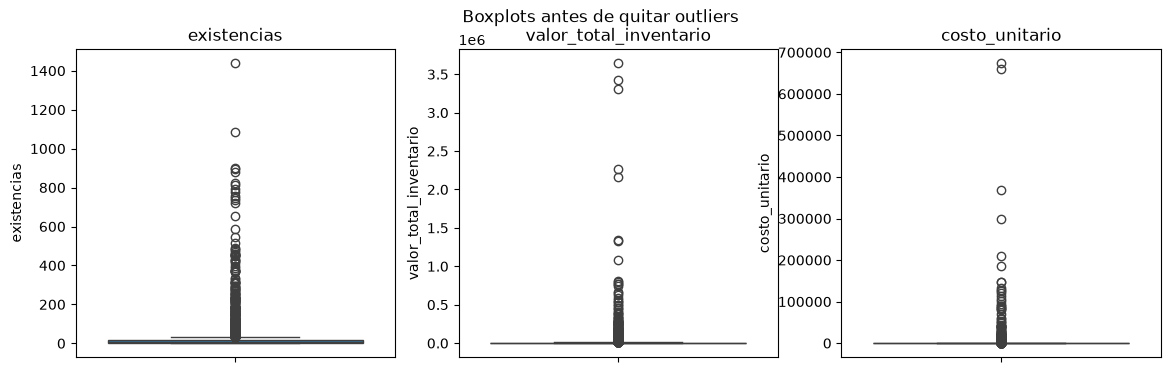

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, col in enumerate(num.columns):
    sns.boxplot(y=num[col], ax=axes[i])
    axes[i].set_title(col)
plt.suptitle('Boxplots antes de quitar outliers')
plt.show()

Hay muchos valores atípicos (los datos tienen mucho sesgo a la derecha). Se usa el método de rango intercuartílico (IQR) en las 3 variables.

In [9]:
Datos_limpios = existencias.copy()

for col in ['existencias', 'valor_total_inventario', 'costo_unitario']:
    q1 = Datos_limpios[col].quantile(0.25)
    q3 = Datos_limpios[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    Datos_limpios = Datos_limpios[(Datos_limpios[col] >= lim_inf) & (Datos_limpios[col] <= lim_sup)]

print('Antes:', existencias.shape)
print('Después:', Datos_limpios.shape)

Antes: (2948, 7)
Después: (1917, 7)


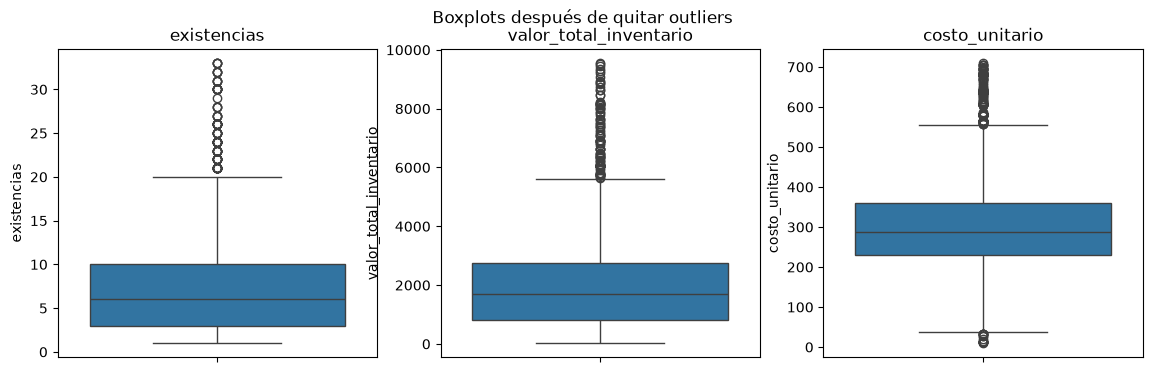

In [10]:
num = Datos_limpios[['existencias', 'valor_total_inventario', 'costo_unitario']]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, col in enumerate(num.columns):
    sns.boxplot(y=num[col], ax=axes[i])
    axes[i].set_title(col)
plt.suptitle('Boxplots después de quitar outliers')
plt.show()

In [11]:
Datos_limpios.to_csv('Existencias_limpias.csv', index=False)

## 2. Correlación

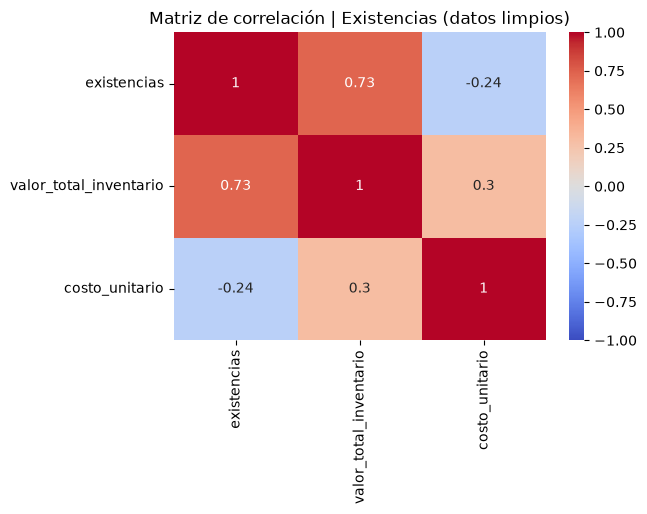

In [12]:
matriz = num.corr()
plt.figure(figsize=(6, 4))
sns.heatmap(matriz, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación | Existencias (datos limpios)')
plt.show()

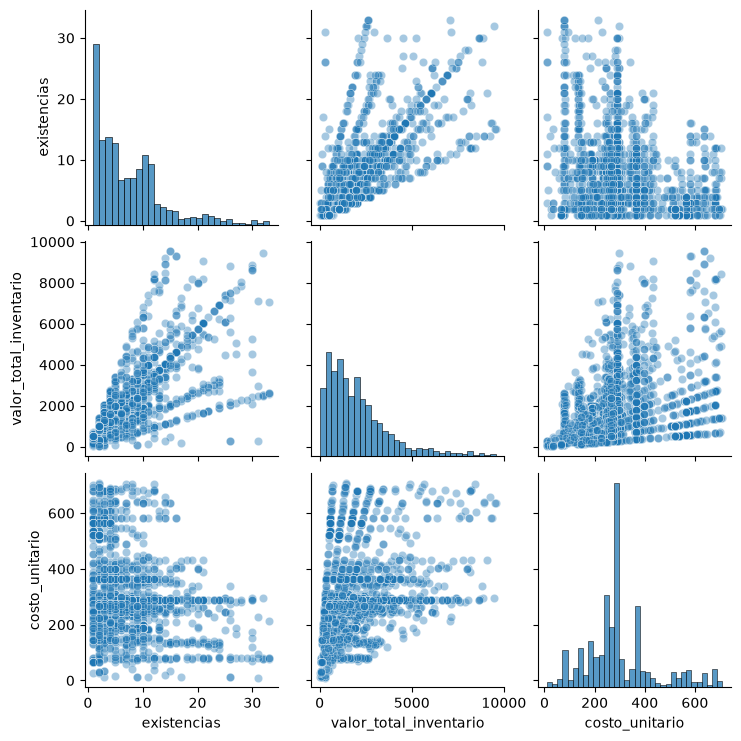

In [13]:
sns.pairplot(num, plot_kws={'alpha': 0.4})
plt.show()

## 3. Regresión No Lineal
Modelos elegidos:
- Función cuadrática: y = a·x² + b·x + c
- Función exponencial: y = a·e^(-b·x) + c

También se calcula el modelo lineal solo como referencia para comparar.

In [14]:
def func1(x, a, b, c):
    return a*x**2 + b*x + c

def func2(x, a, b, c):
    return a*np.exp(-b*x) + c

In [15]:
resultados = []

def regresion_no_lineal(df, var_x, var_y):
    x = df[var_x].values.astype(float)
    y = df[var_y].values

    # Lineal (referencia)
    lineal = LinearRegression().fit(x.reshape(-1, 1), y)
    y_lin = lineal.predict(x.reshape(-1, 1))
    r2_lin = r2_score(y, y_lin)

    # Cuadrática
    param1, cov1 = curve_fit(func1, x, y)
    y_pred1 = func1(x, *param1)
    r2_cuad = r2_score(y, y_pred1)

    # Exponencial (se le dan valores iniciales para que converja)
    p0 = [-y.mean(), 1/x.mean(), y.mean()]
    param2, cov2 = curve_fit(func2, x, y, p0=p0, maxfev=20000)
    y_pred2 = func2(x, *param2)
    r2_exp = r2_score(y, y_pred2)

    print(f'{var_x} vs {var_y}')
    print(f'Cuadrática:  a={param1[0]:.4f}, b={param1[1]:.4f}, c={param1[2]:.4f}')
    print(f'Exponencial: a={param2[0]:.4f}, b={param2[1]:.6f}, c={param2[2]:.4f}')

    for modelo, r2 in [('Lineal (referencia)', r2_lin), ('Cuadrática', r2_cuad), ('Exponencial', r2_exp)]:
        resultados.append({'Variable X': var_x, 'Variable Y': var_y, 'Modelo': modelo,
                           'R2 (determinación)': round(r2, 4), 'R (correlación)': round(np.sqrt(max(r2, 0)), 4)})

    # Grafica
    orden = np.argsort(x)
    plt.figure(figsize=(7, 4))
    plt.scatter(x, y, alpha=0.3, label='Datos reales')
    plt.plot(x[orden], y_lin[orden], color='gray', linestyle='--', label='Lineal')
    plt.plot(x[orden], y_pred1[orden], color='red', label='Cuadrática')
    plt.plot(x[orden], y_pred2[orden], color='green', label='Exponencial')
    plt.xlabel(var_x)
    plt.ylabel(var_y)
    plt.title(f'Regresión No Lineal | {var_x} vs {var_y}')
    plt.legend()
    plt.show()

### Correlación 1: existencias vs valor_total_inventario

existencias vs valor_total_inventario
Cuadrática:  a=-6.8882, b=371.7071, c=-93.3787
Exponencial: a=-6296.7115, b=0.067017, c=6132.0830


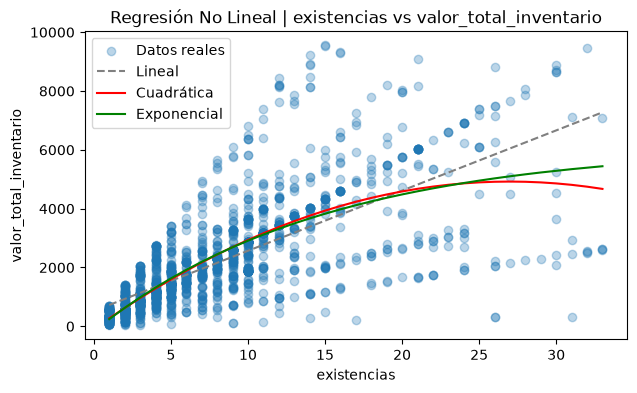

In [16]:
regresion_no_lineal(Datos_limpios, 'existencias', 'valor_total_inventario')

### Correlación 2: costo_unitario vs valor_total_inventario

costo_unitario vs valor_total_inventario
Cuadrática:  a=-0.0063, b=8.2323, c=283.9561
Exponencial: a=-3296.3822, b=0.003756, c=3269.2719


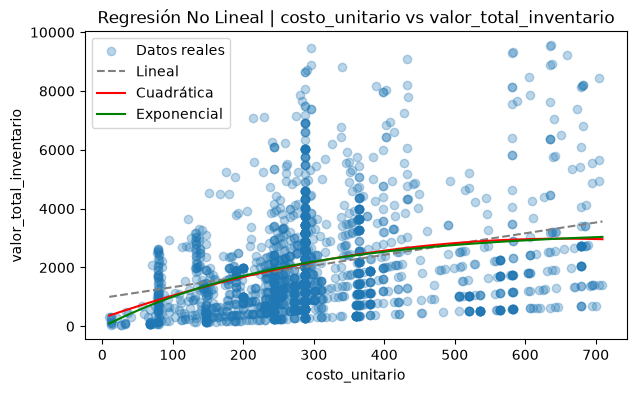

In [17]:
regresion_no_lineal(Datos_limpios, 'costo_unitario', 'valor_total_inventario')

### Correlación 3: existencias vs costo_unitario

existencias vs costo_unitario
Cuadrática:  a=-0.0350, b=-4.7472, c=340.1401
Exponencial: a=-324.9397, b=-0.014388, c=664.6887


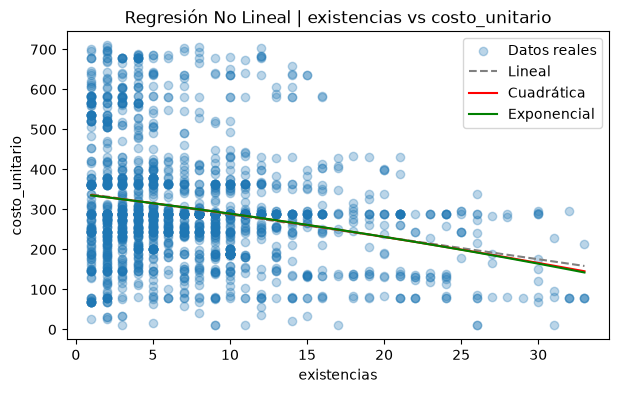

In [18]:
regresion_no_lineal(Datos_limpios, 'existencias', 'costo_unitario')

## 4. Tabla de coeficientes

In [19]:
tabla = pd.DataFrame(resultados)
tabla

,Variable X,Variable Y,Modelo,R2 (determinación),R (correlación)
0,existencias,valor_total_inventario,Lineal (referencia),0.5297,0.7278
1,existencias,valor_total_inventario,Cuadrática,0.5792,0.7611
2,existencias,valor_total_inventario,Exponencial,0.5741,0.7577
3,costo_unitario,valor_total_inventario,Lineal (referencia),0.0914,0.3024
4,costo_unitario,valor_total_inventario,Cuadrática,0.1021,0.3195
5,costo_unitario,valor_total_inventario,Exponencial,0.1039,0.3224
6,existencias,costo_unitario,Lineal (referencia),0.0581,0.2410
7,existencias,costo_unitario,Cuadrática,0.0583,0.2414
8,existencias,costo_unitario,Exponencial,0.0583,0.2414


In [20]:
tabla.pivot_table(index=['Variable X', 'Variable Y'], columns='Modelo', values='R2 (determinación)')

Modelo                                 Cuadrática  Exponencial  \
Variable X     Variable Y                                        
costo_unitario valor_total_inventario      0.1021       0.1039   
existencias    costo_unitario              0.0583       0.0583   
               valor_total_inventario      0.5792       0.5741   

Modelo                                 Lineal (referencia)  
Variable X     Variable Y                                   
costo_unitario valor_total_inventario               0.0914  
existencias    costo_unitario                       0.0581  
               valor_total_inventario               0.5297

In [21]:
tabla.to_csv('Tabla_coeficientes.csv', index=False)

### Comparación con datos sin limpiar
Para ver qué tanto afectan los outliers, se corre la correlación 1 con los datos originales (sin quitar outliers).

existencias vs valor_total_inventario
Cuadrática:  a=-0.0682, b=325.3979, c=14111.9106
Exponencial: a=-78101.7160, b=0.030774, c=77783.3326


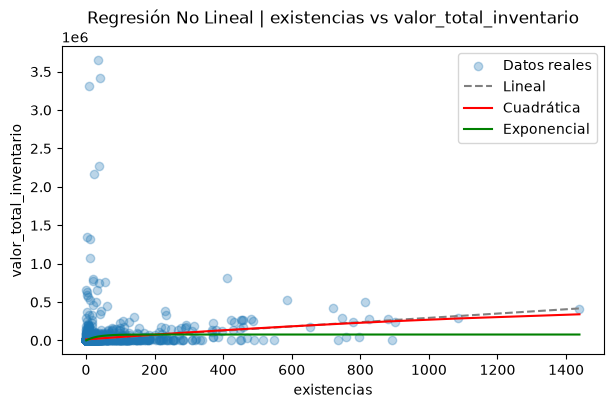

,Variable X,Variable Y,Modelo,R2 (determinación),R (correlación)
0,existencias,valor_total_inventario,Lineal (referencia),0.0259,0.1610
1,existencias,valor_total_inventario,Cuadrática,0.0261,0.1617
2,existencias,valor_total_inventario,Exponencial,0.0229,0.1513


In [22]:
resultados_limpios = resultados.copy()
resultados = []
regresion_no_lineal(existencias, 'existencias', 'valor_total_inventario')
tabla_crudos = pd.DataFrame(resultados)
resultados = resultados_limpios
tabla_crudos

## 5. Conclusiones

1. Correlación 1 (existencias vs valor total): es la mejor relación. Con los datos limpios el modelo lineal da R² = 0.53 y los no lineales lo mejoran un poco: cuadrática R² = 0.579 (R = 0.76) y exponencial R² = 0.574 (R = 0.76). La curva se va aplanando conforme suben las existencias, esto tiene sentido porque los artículos que se tienen en mucha cantidad suelen ser los más baratos.

2. Correlación 2 (costo unitario vs valor total): es débil, R² de 0.10 en ambos modelos. Ya sin outliers el costo por sí solo explica poco del valor total.

3. Correlación 3 (existencias vs costo unitario): prácticamente no hay relación (R² = 0.058). Las curvas quedan casi planas.

4. Outliers: con los datos originales la correlación 1 da R² cerca de 0.026 (igual que en la actividad pasada). Al quitar outliers sube a 0.58, entonces los artículos muy caros o con muchísimas existencias eran los que no dejaban ver la relación.

5. Modelo ganador: la función cuadrática da el R² más alto en la correlación 1, la exponencial gana por muy poco en la 2 y en la 3 quedan empatadas. La diferencia entre las dos es mínima, pero la cuadrática es más fácil de ajustar (no necesita valores iniciales).